### Calculate intrinsic, distshift, and signals-bounds

In [ ]:
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()
prior_z_score = (gene_level_local_metrics.set_index('gene').mean(axis=1)+gene_level_global_metrics.set_index('gene').mean(axis=1))/2
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

import pandas as pd
ps_list = ['k562_gwps','k562_essential','rpe1_essential','hepg2_essential','jurkat_essential', 'hek293_gwps', 'hek293_essential', 'hct116_gwps', 'hct116_essential']

In [19]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

signals_vs_intrinsic = {}
for ps in ps_list:
    signals_vs_intrinsic[ps] = {'WR2':[]}

def compare(df_1, df_2):
    joint_perts = list(set(df_1.index).intersection(df_2.index))
    x = df_1.loc[joint_perts].values[:, 0]
    y = df_2.loc[joint_perts].mean(axis=1).values
    #print(np.isnan(x).sum(), np.isnan(y).sum())
    #print(x.shape, y.shape)
    return pearsonr(x, y).statistic
    
for i in range(len(ps_list)):
    results = pd.read_csv(f'//home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')

    R_weighted_r2 = compare(plot_df, prior_intrinsic_scores)
    signals_vs_intrinsic[ps_list[i]]['WR2'] = R_weighted_r2

lower_bounds_intrinsic = {}
for ps in ps_list:
    lower_bounds_intrinsic[ps] = {'WR2':[]}
    
for i in range(len(ps_list)):
    results = pd.read_csv(f'//home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='dataset_mean'][results.metric=='weighted_r2_deltapert']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')

    R_weighted_r2 = compare(plot_df, prior_intrinsic_scores)
    lower_bounds_intrinsic[ps_list[i]]['WR2'] = R_weighted_r2

upper_bounds_intrinsic = {}
for ps in ps_list:
    upper_bounds_intrinsic[ps] = {'WR2':[]}
    
for i in range(len(ps_list)):
    results = pd.read_csv(f'//home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='technical_duplicate'][results.metric=='weighted_r2_deltapert']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')

    R_weighted_r2 = compare(plot_df, prior_intrinsic_scores)
    upper_bounds_intrinsic[ps_list[i]]['WR2'] = R_weighted_r2

In [20]:
signals_vs_distshift = {}
for ps in ps_list:
    signals_vs_distshift[ps] = {'WR2':[]}

def compare(df_1, df_2):
    joint_perts = list(set(df_1.index).intersection(df_2.index))
    x = df_1.loc[joint_perts].values[:, 0]
    y = df_2.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].max(axis=1).values
    #print(np.isnan(x).sum(), np.isnan(y).sum())
    return pearsonr(x, y).statistic
    
for i in range(len(ps_list)):
    distshift_score = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i]}_distribution_shift_score.csv', index_col=0)
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')

    R_weighted_r2 = compare(plot_df, distshift_score)
    signals_vs_distshift[ps_list[i]]['WR2'] = R_weighted_r2

lower_bounds_distshift = {}
for ps in ps_list:
    lower_bounds_distshift[ps] = {'Pearson_deltactrl':[], 'WR2':[]}
    
for i in range(len(ps_list)):
    distshift_score = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i]}_distribution_shift_score.csv', index_col=0)
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='dataset_mean'][results.metric=='weighted_r2_deltapert']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')

    R_weighted_r2 = compare(plot_df, distshift_score)
    lower_bounds_distshift[ps_list[i]]['WR2'] = R_weighted_r2

upper_bounds_distshift = {}
for ps in ps_list:
    upper_bounds_distshift[ps] = {'Pearson_deltactrl':[], 'WR2':[]}
    
for i in range(len(ps_list)):
    distshift_score = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i]}_distribution_shift_score.csv', index_col=0)
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='technical_duplicate'][results.metric=='weighted_r2_deltapert']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')

    R_weighted_r2 = compare(plot_df, distshift_score)
    upper_bounds_distshift[ps_list[i]]['WR2'] = R_weighted_r2

MannwhitneyuResult(statistic=np.float64(2142820.5), pvalue=np.float64(2.365021567403518e-36))
MannwhitneyuResult(statistic=np.float64(2292543.0), pvalue=np.float64(5.377636647295403e-22))


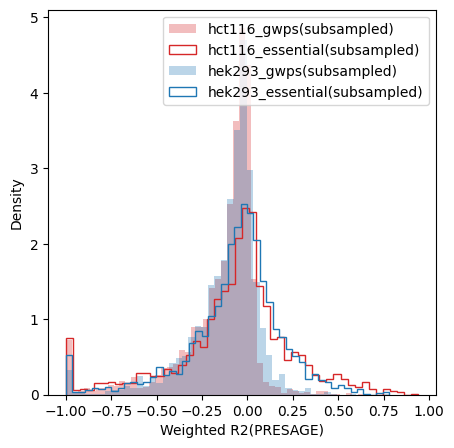

In [21]:
results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/hct116_gwps/detailed_metrics.csv')
hct116_gwps = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/hct116_essential/detailed_metrics.csv')
hct116_essential = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/hek293_gwps/detailed_metrics.csv')
hek293_gwps = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/hek293_essential/detailed_metrics.csv')
hek293_essential = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']

from scipy.stats import mannwhitneyu
print(mannwhitneyu(hct116_gwps.value, hct116_essential.value))
print(mannwhitneyu(hek293_gwps.value, hek293_essential.value))

plt.figure(figsize=(5,5))
plt.hist(hct116_gwps.value, bins=50, label='hct116_gwps(subsampled)', density=True, color='tab:red', alpha=0.3)
plt.hist(hct116_essential.value, bins=50, label='hct116_essential(subsampled)', density=True, histtype='step', color='tab:red')
plt.hist(hek293_gwps.value, bins=50, label='hek293_gwps(subsampled)', density=True, color='tab:blue', alpha=0.3)
plt.hist(hek293_essential.value, bins=50, label='hek293_essential(subsampled)', density=True, histtype='step', color='tab:blue')
plt.xlabel('Weighted R2(PRESAGE)')
plt.ylabel('Density')
plt.legend()
#plt.savefig('./figure_out/Fig.5G_Orion.pdf')

In [22]:
plot_results = [
    [signals_vs_intrinsic['hek293_gwps']['WR2'], signals_vs_distshift['hek293_gwps']['WR2']],
    [signals_vs_intrinsic['hek293_essential']['WR2'], signals_vs_distshift['hek293_essential']['WR2']],
    [signals_vs_intrinsic['hct116_gwps']['WR2'], signals_vs_distshift['hct116_gwps']['WR2']],
    [signals_vs_intrinsic['hct116_essential']['WR2'], signals_vs_distshift['hct116_essential']['WR2']]
    ]

In [23]:
np.array(plot_results)[1]-np.array(plot_results)[0], np.array(plot_results)[3]-np.array(plot_results)[2]

(array([0.05415501, 0.09324472]), array([0.13371973, 0.16226541]))

([<matplotlib.axis.XTick at 0x7f5621d6f700>,
 [Text(0, 0, 'vs. Prior Agreement'), Text(1, 0, 'vs. Sprior')])

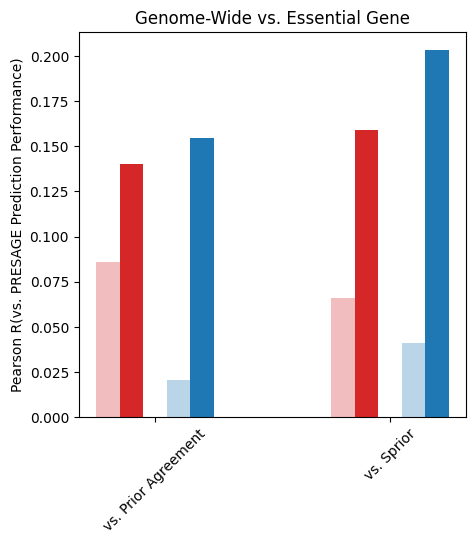

In [24]:
plt.figure(figsize=(5,5))
plt.bar([x-0.2 for x in range(2)], plot_results[0], width=0.1, color='tab:red', alpha=0.3)
plt.bar([x-0.1 for x in range(2)], plot_results[1], width=0.1, color='tab:red')
plt.bar([x+0.1 for x in range(2)], plot_results[2], width=0.1, color='tab:blue', alpha=0.3)
plt.bar([x+0.2 for x in range(2)], plot_results[3], width=0.1, color='tab:blue')
plt.ylabel('Pearson R(vs. PRESAGE Prediction Performance)')
plt.title('Genome-Wide vs. Essential Gene')
plt.xticks(range(2), labels=['vs. Prior Agreement', 'vs. Sprior'], rotation=45)
#plt.savefig('../figure_out/Fig5H_Orion.pdf')

In [25]:
print(pd.DataFrame(signals_vs_intrinsic).loc['WR2'])
print(pd.DataFrame(signals_vs_distshift).loc['WR2'])

k562_gwps           0.408131
k562_essential      0.297129
rpe1_essential      0.338952
hepg2_essential     0.343544
jurkat_essential    0.296937
hek293_gwps         0.085937
hek293_essential    0.140092
hct116_gwps         0.020779
hct116_essential    0.154499
Name: WR2, dtype: float64
k562_gwps           0.267009
k562_essential      0.386316
rpe1_essential      0.335025
hepg2_essential     0.382915
jurkat_essential    0.299455
hek293_gwps         0.065723
hek293_essential    0.158968
hct116_gwps         0.040919
hct116_essential    0.203184
Name: WR2, dtype: float64


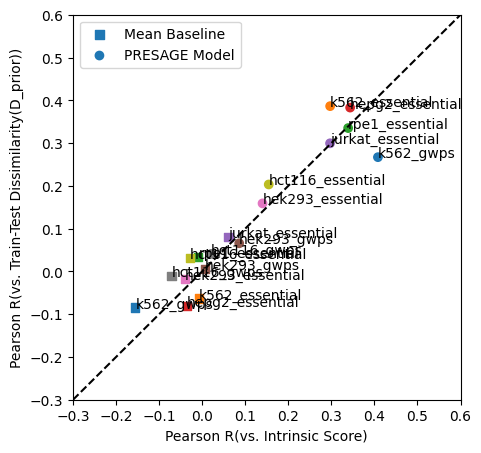

In [26]:
import warnings
warnings.filterwarnings('ignore')

colors_rgba = plt.colormaps['tab10'].colors

plt.figure(figsize=(5,5))
plt.scatter(pd.DataFrame(lower_bounds_intrinsic).loc['WR2'], pd.DataFrame(lower_bounds_distshift).loc['WR2'], label='Mean Baseline', marker='s', c=colors_rgba[:9])
for i in range(9):
    plt.text(pd.DataFrame(lower_bounds_intrinsic).loc['WR2'][i], pd.DataFrame(lower_bounds_distshift).loc['WR2'][i], ps_list[i])
plt.xlim(-0.3, 0.2)
plt.ylim(-0.3, 0.2)
plt.xlabel('Pearson R(vs. Intrinsic Score)')
plt.ylabel('Pearson R(vs. Train-Test Dissimilarity(D_prior))')

plt.scatter(pd.DataFrame(signals_vs_intrinsic).loc['WR2'], pd.DataFrame(signals_vs_distshift).loc['WR2'], label='PRESAGE Model', marker='o', c=colors_rgba[:9])
for i in range(9):
    plt.text(pd.DataFrame(signals_vs_intrinsic).loc['WR2'][i], pd.DataFrame(signals_vs_distshift).loc['WR2'][i], ps_list[i])
plt.xlim(-0.3, 0.6)
plt.ylim(-0.3, 0.6)
plt.xlabel('Pearson R(vs. Intrinsic Score)')
plt.ylabel('Pearson R(vs. Train-Test Dissimilarity(D_prior))')
plt.plot((-0.3, 0.6), (-0.3, 0.6), color='black', linestyle='dashed')
plt.legend()
#plt.savefig('./figure_out/Fig5F.pdf')